# 03 · Which checkout model finds late deliveries?

Compare the course models on the same orders and budget. Hyperparameters are tuned with three expanding folds inside the training window. Average precision (AP) selects the configuration in each family and the family on validation. The later test window answers how many delays a 10% screening budget would have caught.

All imputers, scalers and category encoders are fitted inside the pipeline. At a training cutoff we use only orders already delivered. Validation outcomes used to select the model must also be available before the test window starts.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/checkout_features.json").is_file())
PROCESSED, RESULTS = ROOT / "data/processed", ROOT / "results"
SEED = 5001
schema = json.loads((ROOT / "data/checkout_features.json").read_text())
features = sum(schema.values(), [])
orders = pd.read_parquet(PROCESSED / "orders.parquet").sort_values(["purchased_at", "order_id"])
assert orders.order_id.is_unique and set(orders.columns) == set(features + [
    "order_id", "purchased_at", "label_observed_at", "split", "late",
])

## Establish the historical cutoffs

The date partitions cover the full cohort. A delivery may complete after its purchase partition ends. The rows below show how many outcomes can be used at each decision point. This conservative rule can underrepresent long-running orders near a cutoff.

In [2]:
val_start = orders.loc[orders.split.eq("validation"), "purchased_at"].min().normalize()
test_start = orders.loc[orders.split.eq("test"), "purchased_at"].min().normalize()
train_window = orders.loc[orders.split.eq("train")]
val_window = orders.loc[orders.split.eq("validation")]
train = train_window.loc[train_window.label_observed_at.lt(val_start)].reset_index(drop=True)
valid = val_window.loc[val_window.label_observed_at.lt(test_start)].reset_index(drop=True)
refit = orders.loc[orders.purchased_at.lt(test_start) & orders.label_observed_at.lt(test_start)]
test = orders.loc[orders.split.eq("test")].copy()
availability = pd.DataFrame([
    ("Fit before validation", len(train_window), len(train)),
    ("Select family before test", len(val_window), len(valid)),
    ("Refit before test", len(train_window) + len(val_window), len(refit)),
    ("Evaluate test retrospectively", len(test), len(test)),
], columns=["stage", "purchased", "usable"]).set_index("stage")
availability["withheld"] = availability.purchased - availability.usable
display(availability)
availability.to_csv(RESULTS / "label_availability.csv")
assert train.label_observed_at.max() < val_start <= valid.purchased_at.min()
assert refit.label_observed_at.max() < test_start <= test.purchased_at.min()

,purchased,usable,withheld
stage,,,
Fit before validation,67379,64401,2978
Select family before test,14606,12675,1931
Refit before test,81985,80043,1942
Evaluate test retrospectively,14485,14485,0


## Construct three forward validation folds

Each fold trains on earlier purchases with observed delivery outcomes. The next contiguous purchase block supplies its score. Calendar-day boundaries keep orders from the same date together. GridSearchCV receives the explicit positions below.

In [3]:
purchase_days = train.purchased_at.dt.normalize()
starts = [purchase_days.iloc[int(len(train) * fraction)] for fraction in (0.40, 0.60, 0.80)]
folds, fold_log = [], []
for start, stop in zip(starts, starts[1:] + [val_start]):
    fit_idx = np.flatnonzero((train.purchased_at < start) & (train.label_observed_at < start))
    eval_idx = np.flatnonzero((train.purchased_at >= start) & (train.purchased_at < stop))
    fit_part, eval_part = train.iloc[fit_idx], train.iloc[eval_idx]
    assert fit_part.label_observed_at.max() < start <= eval_part.purchased_at.min()
    assert fit_part.purchased_at.max() < eval_part.purchased_at.min()
    assert fit_part.late.nunique() == eval_part.late.nunique() == 2
    folds.append((fit_idx, eval_idx))
    fold_log.append((start.date(), stop.date(), len(fit_idx), len(eval_idx),
                     fit_part.late.mean(), eval_part.late.mean()))
fold_table = pd.DataFrame(fold_log, columns=["score_from", "score_before", "fit_orders", "score_orders",
                                             "fit_late_rate", "score_late_rate"])
display(fold_table.style.format({"fit_late_rate": "{:.2%}", "score_late_rate": "{:.2%}"}))
fold_table.to_csv(RESULTS / "training_cv_folds.csv", index=False)

,score_from,score_before,fit_orders,score_orders,fit_late_rate,score_late_rate
0,2017-09-26,2017-12-02,24132,12702,3.09%,8.94%
1,2017-12-02,2018-02-04,34272,12921,3.34%,6.21%
2,2018-02-04,2018-04-15,48448,13036,4.97%,11.54%


## Define the predictors and model families

Skewed nonnegative amounts, counts, dimensions and distance are log-transformed. Continuous inputs are standardized. Infrequent categories are pooled within the fitted sample. The tree and logistic pipelines share the same checkout fields. The gradient-boosted model uses a dense matrix and a fixed number of boosting rounds.

In [4]:
def make_preprocessor(dense=False):
    log_scale = make_pipeline(SimpleImputer(strategy="median"),
                              FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                              StandardScaler())
    scale = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    category = make_pipeline(SimpleImputer(strategy="constant", fill_value="Unknown"),
                             OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=75,
                                           max_categories=30, sparse_output=True))
    return ColumnTransformer([("log", log_scale, schema["log_numeric"]),
                              ("num", scale, schema["numeric"]),
                              ("cat", category, schema["categorical"])],
                             sparse_threshold=0 if dense else 1.0)

families = {
    "Logistic": (LogisticRegression(penalty=None, max_iter=1200, tol=0.0005), {}),
    "Lasso logistic": (LogisticRegression(penalty="l1", solver="liblinear", max_iter=800, random_state=SEED),
                       {"model__C": [0.03, 0.3, 3.0]}),
    "Ridge logistic": (LogisticRegression(penalty="l2", max_iter=1000),
                       {"model__C": [0.03, 0.3, 3.0]}),
    "Pruned tree": (DecisionTreeClassifier(min_samples_leaf=50, ccp_alpha=0.00002, random_state=SEED),
                    {"model__max_depth": [3, 6, 10]}),
    "Random forest": (RandomForestClassifier(n_estimators=100, min_samples_leaf=20, max_features="sqrt",
                                              random_state=SEED, n_jobs=2),
                      {"model__max_depth": [8, None]}),
    "Gradient boosting": (HistGradientBoostingClassifier(max_iter=100, max_leaf_nodes=15, min_samples_leaf=50,
                                                        l2_regularization=1, early_stopping=False, random_state=SEED),
                          {"model__learning_rate": [0.03, 0.08, 0.15]}),
}

## Select hyperparameters inside training

C is inverse penalty strength, so smaller values shrink logistic coefficients more strongly. Depth limits tree complexity and learning rate controls each boosting step. All candidates and the three individual fold scores are saved for sensitivity analysis. Folds receive equal weight in the mean.

In [5]:
models, candidates, settings = {}, [], {}
with threadpool_limits(limits=2):
    for family, (estimator, grid) in families.items():
        model = Pipeline([("prepare", make_preprocessor(dense=family == "Gradient boosting")),
                          ("model", estimator)])
        search = GridSearchCV(model, grid, scoring="average_precision", cv=folds,
                              refit=True, n_jobs=1, error_score="raise")
        search.fit(train[features], train.late)
        models[family] = search.best_estimator_
        settings[family] = search.best_params_
        for pos, params in enumerate(search.cv_results_["params"]):
            row = {"family": family, "parameters": json.dumps(params, sort_keys=True),
                   "mean_ap": search.cv_results_["mean_test_score"][pos],
                   "selected": pos == search.best_index_}
            for f in range(len(folds)):
                row[f"fold_{f + 1}_ap"] = search.cv_results_[f"split{f}_test_score"][pos]
            candidates.append(row)
sensitivity = pd.DataFrame(candidates)
sensitivity.to_csv(RESULTS / "cv_sensitivity.csv", index=False)
display(sensitivity.round(4))

,family,parameters,mean_ap,selected,fold_1_ap,fold_2_ap,fold_3_ap
0,Logistic,{},0.1557,True,0.1295,0.0983,0.2395
1,Lasso logistic,"{""model__C"": 0.03}",0.1708,True,0.1406,0.1082,0.2637
2,Lasso logistic,"{""model__C"": 0.3}",0.1614,False,0.1356,0.1007,0.2480
3,Lasso logistic,"{""model__C"": 3.0}",0.1565,False,0.1307,0.0986,0.2404
4,Ridge logistic,"{""model__C"": 0.03}",0.1667,True,0.1400,0.1001,0.2599
5,Ridge logistic,"{""model__C"": 0.3}",0.1587,False,0.1318,0.1001,0.2442
6,Ridge logistic,"{""model__C"": 3.0}",0.1561,False,0.1298,0.0985,0.2400
7,Pruned tree,"{""model__max_depth"": 3}",0.0923,False,0.0904,0.0712,0.1154
8,Pruned tree,"{""model__max_depth"": 6}",0.1013,False,0.0905,0.0707,0.1428
9,Pruned tree,"{""model__max_depth"": 10}",0.1028,True,0.0904,0.0882,0.1296


## Score a fixed screening budget

Flag exactly `floor(N / 10)` orders. Sort by descending risk, then by anonymized order ID for reproducible ties, which matter especially for a single tree. Recall is the number of late orders flagged divided by **all** late orders. Precision divides the same count by flagged orders. Lift compares precision with the period's delay prevalence. AP is the non-interpolated precision–recall summary used throughout.

In [6]:
def evaluate(frame, scores):
    scored = frame[["order_id", "late"]].copy()
    scored["risk"] = np.asarray(scores)
    assert scored.risk.between(0, 1).all() and scored.late.nunique() == 2
    ranked = scored.sort_values(["risk", "order_id"], ascending=[False, True])
    k = len(ranked) // 10
    assert k > 0
    alerts = ranked.iloc[:k]
    caught, total_late = int(alerts.late.sum()), int(scored.late.sum())
    prevalence = scored.late.mean()
    metrics = {
        "orders": len(scored), "late_orders": total_late, "flagged": k, "caught": caught,
        "prevalence": prevalence, "roc_auc": roc_auc_score(scored.late, scored.risk),
        "ap": average_precision_score(scored.late, scored.risk), "recall_at_10pct": caught / total_late,
        "precision_at_10pct": caught / k, "lift_at_10pct": (caught / k) / prevalence,
    }
    scored["flagged"] = scored.index.isin(alerts.index)
    return metrics, scored

val_rows, val_predictions = {}, {}
with threadpool_limits(limits=2):
    for family, model in models.items():
        val_rows[family], val_predictions[family] = evaluate(valid, model.predict_proba(valid[features])[:, 1])
val_metrics = pd.DataFrame(val_rows).T.rename_axis("family")
ranked_names = val_metrics.sort_values("ap", ascending=False, kind="stable").index
selected = ranked_names[0]
linear = next(name for name in ranked_names if name in {"Lasso logistic", "Ridge logistic"})
ensemble = next(name for name in ranked_names if name in {"Random forest", "Gradient boosting"})
for col in ["orders", "late_orders", "flagged", "caught"]:
    val_metrics[col] = val_metrics[col].astype(int)
val_metrics.to_csv(RESULTS / "validation_metrics.csv")
display(val_metrics.loc[ranked_names, ["roc_auc", "ap", "recall_at_10pct", "precision_at_10pct"]].round(4))
print(f"Selected by validation AP: {selected}. Regularized logistic comparator: {linear}.")

,roc_auc,ap,recall_at_10pct,precision_at_10pct
family,,,,
Logistic,0.7753,0.1236,0.3450,0.1476
Ridge logistic,0.7723,0.1208,0.3376,0.1444
Lasso logistic,0.7714,0.1193,0.3192,0.1365
Gradient boosting,0.7201,0.1112,0.2731,0.1168
Random forest,0.7149,0.0990,0.2989,0.1279
Pruned tree,0.5600,0.0610,0.2472,0.1058


Selected by validation AP: Logistic. Regularized logistic comparator: Ridge logistic.


## Freeze the comparison and refit at the test cutoff

The family and hyperparameters are fixed before scoring test outcomes. Refit each prespecified family on all available pre-test labels. The selected model and logistic comparator saved for notebook 04 are their *earlier, training-only fits*, so their validation diagnostics remain out of sample.

In [7]:
record = {"selection_metric": "average_precision", "selected_family": selected,
          "regularized_logistic_comparator": linear, "ensemble_for_interactions": ensemble, "hyperparameters": settings,
          "validation_start": str(val_start.date()), "test_start": str(test_start.date()), "seed": SEED}
(RESULTS / "model_selection.json").write_text(json.dumps(record, indent=2) + "\n")
joblib.dump({"selected": models[selected], "logistic": models[linear], "ensemble": models[ensemble]},
            PROCESSED / "validation_models.joblib")
val_predictions[selected].to_parquet(PROCESSED / "validation_predictions.parquet", index=False)

test_rows = {}
with threadpool_limits(limits=2):
    for family, prototype in models.items():
        fitted = clone(prototype).fit(refit[features], refit.late)
        test_rows[family], _ = evaluate(test, fitted.predict_proba(test[features])[:, 1])
test_metrics = pd.DataFrame(test_rows).T.rename_axis("family")
test_metrics["ap_difference_vs_regularized"] = test_metrics.ap - test_metrics.loc[linear, "ap"]
for table in [val_metrics, test_metrics]:
    assert (table.caught <= table.late_orders).all() and (table.caught <= table.flagged).all()
    assert np.allclose(table.recall_at_10pct, table.caught / table.late_orders)
    assert (table.flagged == table.orders // 10).all()
for col in ["orders", "late_orders", "flagged", "caught"]:
    test_metrics[col] = test_metrics[col].astype(int)
test_metrics.to_csv(RESULTS / "test_metrics.csv")
display(test_metrics[["roc_auc", "ap", "ap_difference_vs_regularized", "recall_at_10pct",
                      "precision_at_10pct", "lift_at_10pct", "caught"]].round(4))

,roc_auc,ap,ap_difference_vs_regularized,recall_at_10pct,precision_at_10pct,lift_at_10pct,caught
family,,,,,,,
Logistic,0.6418,0.0798,0.0068,0.1968,0.0843,1.9684,122
Lasso logistic,0.6074,0.0710,-0.0021,0.1661,0.0711,1.6619,103
Ridge logistic,0.6212,0.0731,0.0000,0.1790,0.0767,1.7909,111
Pruned tree,0.5794,0.0548,-0.0182,0.1097,0.0470,1.0972,68
Random forest,0.4847,0.0544,-0.0187,0.1516,0.0649,1.5167,94
Gradient boosting,0.5841,0.0570,-0.0161,0.1403,0.0601,1.4037,87


## Delays reached by a 10% alert budget

The highlighted row was selected on validation. The dashed line is the expected recall from choosing the same number of orders uniformly at random. Ranking a historical window at once is a retrospective capacity benchmark. A daily alert queue would require ranking orders within each day.

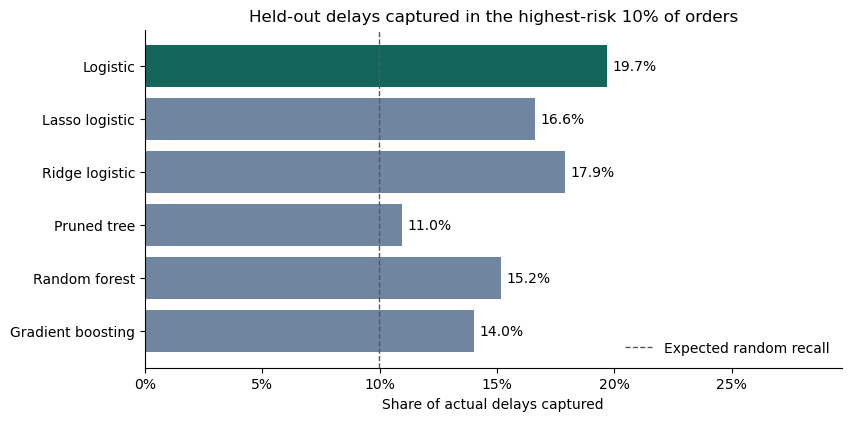

Logistic: flagged 1,448 / 14,485 test orders and found 122 / 620 late deliveries (19.7% recall).
Delay rate 4.3%; precision among alerts 8.4%; lift 1.97×.


In [8]:
fig, ax = plt.subplots(figsize=(8.4, 4.1), constrained_layout=True)
scores = test_metrics.recall_at_10pct.iloc[::-1]
bars = ax.barh(scores.index, scores, color=["#14665d" if n == selected else "#7086a0" for n in scores.index])
ax.bar_label(bars, labels=[f"{v:.1%}" for v in scores], padding=4)
random_recall = (len(test) // 10) / len(test)
ax.axvline(random_recall, color="#55565e", linestyle="--", lw=1, label="Expected random recall")
ax.set(title="Held-out delays captured in the highest-risk 10% of orders", xlabel="Share of actual delays captured",
       xlim=(0, max(scores.max() + 0.10, 0.25)))
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
fig.savefig(RESULTS / "test_top_decile_recall.png", dpi=140)
plt.show()
r = test_metrics.loc[selected]
print(f"{selected}: flagged {int(r.flagged):,} / {int(r.orders):,} test orders and found "
      f"{int(r.caught):,} / {int(r.late_orders):,} late deliveries ({r.recall_at_10pct:.1%} recall).")
print(f"Delay rate {r.prevalence:.1%}; precision among alerts {r.precision_at_10pct:.1%}; lift {r.lift_at_10pct:.2f}×.")

The validation-selected logistic model caught 122 of 620 test-period delays. Its AP fell from 0.124 on the label-available validation cohort to 0.080 on test. All three tree models had lower test AP than the validation-selected regularized comparator, Ridge (0.073). These estimates describe one chronological holdout and one capacity budget.